In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración global de gráficas
sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

# Etiquetas cortas para estratos
ESTRATO_LABELS = {"1.º – 4.º semestre": "1.º–4.º sem.", "5.º – 9.º semestre": "5.º–9.º sem."}

## Aquí se importa el dataset desde el Google Sheets "encuesta_sii"


In [3]:
sheet_name = 'encuesta_sii'
sheet_id = '1B2kJwlCVK_m3iViacA9sYMNRXANDAIi5-F6cnWAXvug'
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}"
data = pd.read_csv(url)
data

,Marca temporal,¿Estás actualmente inscrito(a) en Ingeniería en Sistemas Computacionales del ITVER?,"Durante este ciclo escolar, ¿realizaste al menos un proceso de reinscripción o consulta en el SII?",¿En que bloque de semestre te encuentras?,Número de control,¿Con qué frecuencia entras al SII?,¿Desde qué dispositivo usas principalmente el SII?,¿Qué trámites has realizado en el SII? (Puedes elegir varios),"Del 1 al 5, ¿Qué tan satisfecho(a) estás con el SII en general?","Del 1 al 5, ¿Qué tan satisfecho(a) estás con la facilidad de uso y navegación del SII?",...,"Del 1 al 5, ¿Qué tan satisfecho(a) estás con el agendado de citas en departamentos? (omítela si no lo has usado)","En términos generales, ¿te consideras satisfecho(a) con el SII?","Comparado con hace un año, ¿Cómo consideras que ha cambiado el SII? (omítela si no es tu caso)",¿Con qué frecuencia has tenido problemas de conexión o caídas del SII?,"¿Has detectado información tuya incorrecta o inconsistente en el SII (calificaciones, materias, datos personales)?",¿Qué problemas has experimentando en el SII? (puedes elegir varios),"En el último periodo de reinscripción, ¿pudiste completar tu proceso en el SII? (omite si es no es tu caso).",¿Has tenido que acudir presencialmente por algo que debería resolverse desde el SII?,¿Qué aspecto del SII debería mejorarse primero?,"Si quieres, cuéntanos brevemente tu peor (o mejor) experiencia con el SII."
0,1,Sí,Sí,1.º – 4.º semestre,25010703,Algunas veces al mes,Computadora o laptop,Consultar calificaciones,5,2,...,NaN,Sí,Sigue igual,Siempre,Nunca,"Fallas al seleccionar materias, Errores de vis...","Sí, sin problemas",No,Diseño y facilidad de uso,NaN
1,2,Sí,Sí,1.º – 4.º semestre,25010383,"Solo en periodos clave (inscripción, calificac...",Computadora y celular por igual,Consultar datos personales,5,3,...,NaN,Sí,Sigue igual,Frecuentemente,Nunca,"Mala adaptación al celular, Fallas al agendar ...","No, necesité apoyo presencial o de un tercero",Sí,Proceso de reinscripción,Deberían mejorar la velocidad de carga de la p...
2,3,Sí,Sí,1.º – 4.º semestre,24010096,Todos los días,Computadora y celular por igual,"Consultar o actualizar datos socioeconómicos, ...",5,3,...,NaN,Sí,Ha mejorado,Algunas veces,Una vez,"Caídas o falta de conexión con el sistema, Fal...","Sí, sin problemas",No,Estabilidad y velocidad,El diseño parece de hace 15 años.
3,4,Sí,Sí,1.º – 4.º semestre,26010129,Varias veces por semana,Computadora o laptop,"Consultar datos personales, Consultar o actual...",5,2,...,5.0,Sí,Sigue igual,Algunas veces,Nunca,Fallas al agendar citas,"No, necesité apoyo presencial o de un tercero",Sí,Proceso de reinscripción,Deberían mejorar la velocidad de carga de la p...
4,5,Sí,Sí,1.º – 4.º semestre,26010928,Algunas veces al mes,Celular,"Agendar citas en departamentos, Consultar o ac...",5,2,...,3.0,Sí,Sigue igual,Algunas veces,Una vez,Información incorrecta o desactualizada,"Sí, pero con dificultades o varios intentos",Sí,Proceso de reinscripción,Deberían mejorar la velocidad de carga de la p...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,123,Sí,Sí,5.º – 9.º semestre,23010441,Algunas veces al mes,Computadora o laptop,Consultar o actualizar datos socioeconómicos,1,4,...,3.0,No,Ha mejorado,Algunas veces,Nunca,"Lentitud al cargar las páginas, Fallas al sele...","Sí, pero con dificultades o varios intentos",No,Estabilidad y velocidad,NaN
123,124,Sí,Sí,5.º – 9.º semestre,24020365,Algunas veces al mes,Celular,"Reinscripción / selección de materias, Consult...",1,3,...,1.0,No,Sigue igual,Algunas veces,Nunca,Mala adaptación al celular,"Sí, pero con dificultades o varios intentos",No,Diseño y facilidad de uso,"Todo bien, cumple su función."
124,125,Sí,Sí,5.º – 9.º semestre,23020487,Algunas veces al mes,Computadora o laptop,"Consultar calificaciones, Consultar horario o ...",1,2,...,NaN,No,Ha empeorado,Algunas veces,Nunca,No he tenido problemas,"Sí, sin problemas",No,Estabilidad y velocidad,NaN
125,126,Sí,Sí

## Se realiza una limpieza general del dataset

In [4]:
# Se realiza una copia llamada df.
df = data.copy()
# Se renombran las columnas del dataset para mayor facilidad.
nombres = ["id_respuesta", "inscrito", "uso_ciclo", "bloque",
           "num_control", "frecuencia_uso", "dispositivo", "tramites",
           "sat_general", "sat_facilidad", "sat_diseno", "sat_rendimiento",
           "sat_disponibilidad", "sat_info", "sat_seguridad",
           "sat_calificaciones", "sat_reinscripcion", "sat_citas",
           "satisfecho_binario", "evolucion", "freq_caidas", "freq_inconsistencias",
           "problemas_tipos", "reinscripcion_exito", "acudio_presencial",
           "mejora_prioritaria", "comentarios"]
df.columns = nombres



In [5]:
# Se eliminan respuestas duplicadas por númnero de control.
df["num_control"] = df["num_control"].astype(str)
print("Duplicados:", df["num_control"].duplicated().sum())
df = df.drop_duplicates(subset="num_control", keep="first")

Duplicados: 0


In [6]:
# Las escalas 1-5 como enteros que aceptan nulos
cols_sat = [c for c in df.columns if c.startswith("sat_")]
df[cols_sat] = df[cols_sat].astype("Int64")

In [7]:
# Se ordenan las categorías
df["freq_caidas"] = pd.Categorical(df["freq_caidas"], ordered=True,
    categories=["Nunca", "Rara vez", "Algunas veces", "Frecuentemente", "Siempre"])
df["freq_inconsistencias"] = pd.Categorical(df["freq_inconsistencias"], ordered=True,
    categories=["Nunca", "Una vez", "Varias veces"])

In [8]:
# las respuestas 'Sí' y 'No' se convierten a booleanos.
for c in ["satisfecho_binario", "acudio_presencial"]:
    df[c] = df[c].map({"Sí": True, "No": False})

In [9]:
# Se normalizan las opciones de opción múltiple añadiendo prefijos y concatenandolos.
tramites = df["tramites"].str.get_dummies(sep=", ").add_prefix("tramite_")
problemas = df["problemas_tipos"].str.get_dummies(sep=", ").add_prefix("problema_")
df = pd.concat([df, tramites, problemas], axis=1)

In [10]:
# Se eliminan los datos nulos del texto libre y se sustituyen como 'Sin comentario'
df["comentarios"] = df["comentarios"].fillna("Sin comentario")

In [11]:
#Impresión del la información del dataset
df.info()
df

<class 'pandas.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 42 columns):
 #   Column                                                Non-Null Count  Dtype   
---  ------                                                --------------  -----   
 0   id_respuesta                                          127 non-null    int64   
 1   inscrito                                              127 non-null    str     
 2   uso_ciclo                                             127 non-null    str     
 3   bloque                                                127 non-null    str     
 4   num_control                                           127 non-null    str     
 5   frecuencia_uso                                        127 non-null    str     
 6   dispositivo                                           127 non-null    str     
 7   tramites                                              127 non-null    str     
 8   sat_general                                           127 non

,id_respuesta,inscrito,uso_ciclo,bloque,num_control,frecuencia_uso,dispositivo,tramites,sat_general,sat_facilidad,...,tramite_Reinscripción / selección de materias,problema_Caídas o falta de conexión con el sistema,problema_Errores de visualización o de diseño,problema_Fallas al agendar citas,problema_Fallas al seleccionar materias,problema_Información incorrecta o desactualizada,problema_Lentitud al cargar las páginas,problema_Mala adaptación al celular,problema_No he tenido problemas,problema_Problemas de acceso (usuario o contraseña)
0,1,Sí,Sí,1.º – 4.º semestre,25010703,Algunas veces al mes,Computadora o laptop,Consultar calificaciones,5,2,...,0,1,1,0,1,0,0,0,0,0
1,2,Sí,Sí,1.º – 4.º semestre,25010383,"Solo en periodos clave (inscripción, calificac...",Computadora y celular por igual,Consultar datos personales,5,3,...,0,0,1,1,0,0,0,1,0,0
2,3,Sí,Sí,1.º – 4.º semestre,24010096,Todos los días,Computadora y celular por igual,"Consultar o actualizar datos socioeconómicos, ...",5,3,...,0,1,0,1,0,0,0,0,0,0
3,4,Sí,Sí,1.º – 4.º semestre,26010129,Varias veces por semana,Computadora o laptop,"Consultar datos personales, Consultar o actual...",5,2,...,0,0,0,1,0,0,0,0,0,0
4,5,Sí,Sí,1.º – 4.º semestre,26010928,Algunas veces al mes,Celular,"Agendar citas en departamentos, Consultar o ac...",5,2,...,1,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,123,Sí,Sí,5.º – 9.º semestre,23010441,Algunas veces al mes,Computadora o laptop,Consultar o actualizar datos socioeconómicos,1,4,...,0,0,0,0,1,0,1,0,0,0
123,124,Sí,Sí,5.º – 9.º semestre,24020365,Algunas veces al mes,Celular,"Reinscripción / selección de materias, Consult...",1,3,...,1,0,0,0,0,0,0,1,0,0
124,125,Sí,Sí,5.º – 9.º semestre,23020487,Algunas veces al mes,Computadora o laptop,"Consultar calificaciones, Consultar horario o ...",1,2,...,0,0,0,0,0,0,0,0,1,0
125,126,Sí,Sí,5.º – 9.º semestre,23010770,"Solo en periodos clave (inscripción, calificac...",Computadora o laptop,"Agendar citas en departamentos, Consultar cali...",1,4,...,0,0,0,0,1,0,0,1,0,0


## Análisis gráfico por estratos

A continuación se presentan gráficas comparativas entre los bloques **1.º–4.º semestre** y **5.º–9.º semestre** para cada pregunta de la encuesta.

---

### 1.1 ¿Con qué frecuencia entras al SII?

Se contabiliza la cantidad y porcentaje de alumnos en cada categoría de frecuencia, separados por estrato.

Frecuencias absolutas:
                                                    1.º–4.º sem.  5.º–9.º sem.
frecuencia_uso                                                                
Solo en periodos clave (inscripción, calificaci...             0             0
Algunas veces al mes                                          27            23
Varias veces por semana                                       17            13
Casi todos los días                                            0             0

Porcentajes por estrato:
                                                    1.º–4.º sem.  5.º–9.º sem.
frecuencia_uso                                                                
Solo en periodos clave (inscripción, calificaci...           0.0           0.0
Algunas veces al mes                                        61.4          63.9
Varias veces por semana                                     38.6          36.1
Casi todos los días                                          0.0           0.0


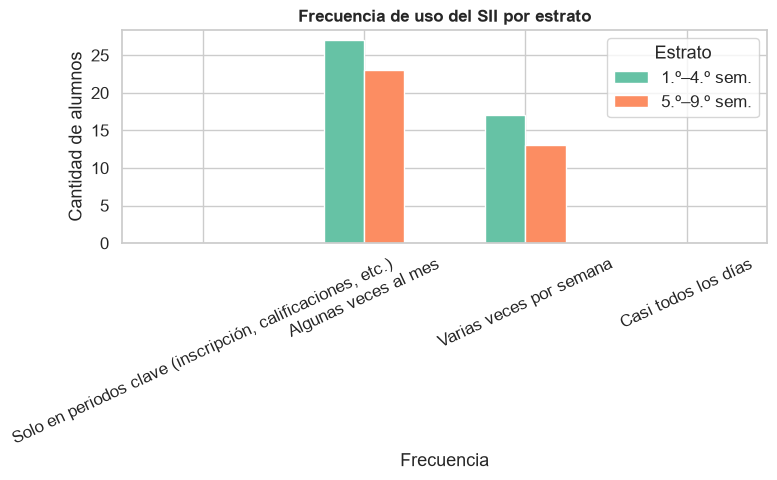

In [12]:
# --- 1.1 Frecuencia de uso del SII: Frecuencias y Gráfica de barras ---
orden_freq = [
    "Solo en periodos clave (inscripción, calificaciones, etc.)",
    "Algunas veces al mes",
    "Varias veces por semana",
    "Casi todos los días"
]

# Tabla cruzada de frecuencias
ct_freq = pd.crosstab(df["frecuencia_uso"], df["bloque"])
ct_freq = ct_freq.reindex(orden_freq).fillna(0).astype(int)
ct_freq.columns = [ESTRATO_LABELS.get(c, c) for c in ct_freq.columns]

print("Frecuencias absolutas:")
print(ct_freq)
print()

# Porcentajes por estrato
ct_pct = ct_freq.div(ct_freq.sum()) * 100
print("Porcentajes por estrato:")
print(ct_pct.round(1))

# Gráfica de barras agrupadas independiente
fig, ax = plt.subplots(figsize=(8, 5))
ct_freq.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Frecuencia de uso del SII por estrato", fontsize=12, fontweight="bold")
ax.set_xlabel("Frecuencia")
ax.set_ylabel("Cantidad de alumnos")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Estrato")
plt.tight_layout()
plt.show()

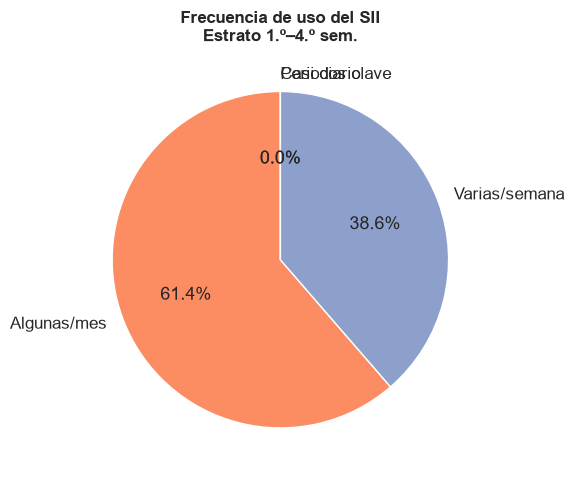

In [13]:
# --- 1.1 Gráfica circular: Estrato 1.º – 4.º semestre ---
labels_cortas = ["Periodos clave", "Algunas/mes", "Varias/semana", "Casi diario"]
col1 = ct_freq.columns[0]

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(ct_freq[col1], labels=labels_cortas, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
ax.set_title(f"Frecuencia de uso del SII\nEstrato {col1}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

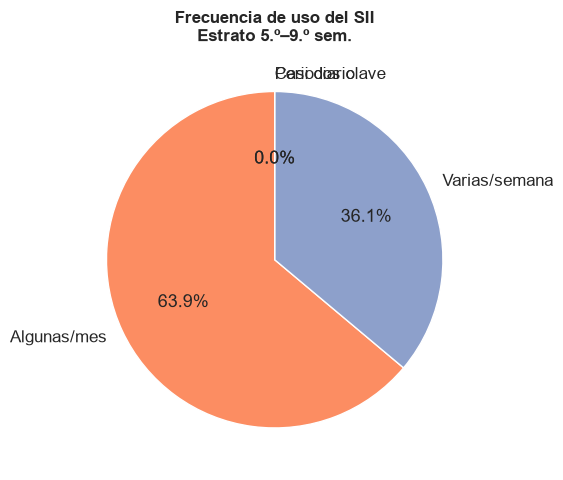

In [14]:
# --- 1.1 Gráfica circular: Estrato 5.º – 9.º semestre ---
labels_cortas = ["Periodos clave", "Algunas/mes", "Varias/semana", "Casi diario"]
col2 = ct_freq.columns[1]

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(ct_freq[col2], labels=labels_cortas, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
ax.set_title(f"Frecuencia de uso del SII\nEstrato {col2}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 1.2 ¿Desde qué dispositivo usas principalmente el SII?

Se contabiliza la cantidad y porcentaje de alumnos según el dispositivo principal, separados por estrato.

Frecuencias absolutas:
                                 1.º–4.º sem.  5.º–9.º sem.
dispositivo                                                
Celular                                    14            10
Computadora o laptop                       38            32
Computadora y celular por igual            14            10
Tablet                                      4             5

Porcentajes por estrato:
                                 1.º–4.º sem.  5.º–9.º sem.
dispositivo                                                
Celular                                  20.0          17.5
Computadora o laptop                     54.3          56.1
Computadora y celular por igual          20.0          17.5
Tablet                                    5.7           8.8


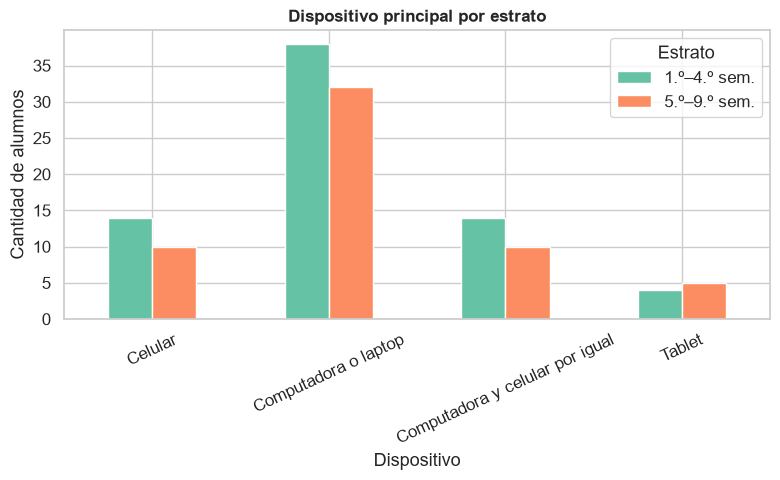

In [15]:
# --- 1.2 Dispositivo principal: Frecuencias y Gráfica de barras ---
ct_disp = pd.crosstab(df["dispositivo"], df["bloque"])
ct_disp.columns = [ESTRATO_LABELS.get(c, c) for c in ct_disp.columns]

print("Frecuencias absolutas:")
print(ct_disp)
print()

ct_disp_pct = ct_disp.div(ct_disp.sum()) * 100
print("Porcentajes por estrato:")
print(ct_disp_pct.round(1))

# Gráfica de barras agrupadas independiente
fig, ax = plt.subplots(figsize=(8, 5))
ct_disp.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Dispositivo principal por estrato", fontsize=12, fontweight="bold")
ax.set_xlabel("Dispositivo")
ax.set_ylabel("Cantidad de alumnos")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Estrato")
plt.tight_layout()
plt.show()

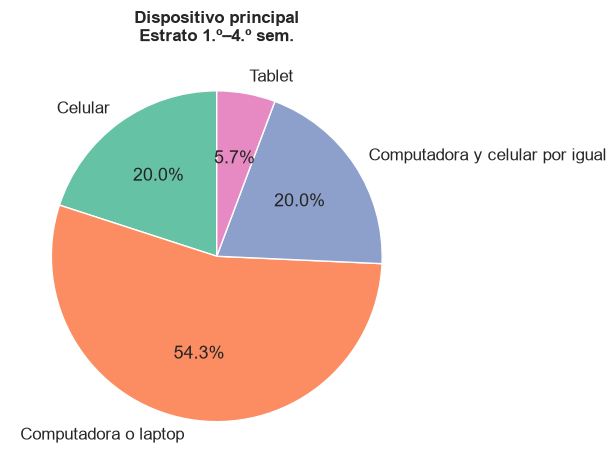

In [16]:
# --- 1.2 Gráfica circular: Estrato 1.º – 4.º semestre ---
col1 = ct_disp.columns[0]

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(ct_disp[col1], labels=ct_disp.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
ax.set_title(f"Dispositivo principal\nEstrato {col1}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

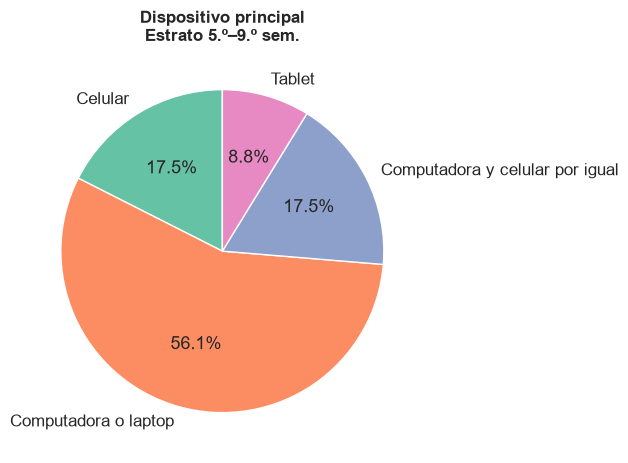

In [17]:
# --- 1.2 Gráfica circular: Estrato 5.º – 9.º semestre ---
col2 = ct_disp.columns[1]

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(ct_disp[col2], labels=ct_disp.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
ax.set_title(f"Dispositivo principal\nEstrato {col2}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 1.3 ¿Qué trámites has realizado en el SII? (opción múltiple)

Al ser una pregunta de opción múltiple, se cuenta cuántos alumnos marcaron cada trámite por estrato. Las proporciones no suman 100% porque un alumno puede marcar varios.

Cantidad de alumnos que realizaron cada trámite:
                                              1.º–4.º sem.  5.º–9.º sem.
Agendar citas en departamentos                          31            25
Consultar calificaciones                                29            20
Consultar datos personales                              31            28
Consultar horario o kárdex                              23            30
Consultar o actualizar datos socioeconómicos            25            23
Reinscripción / selección de materias                   23            26


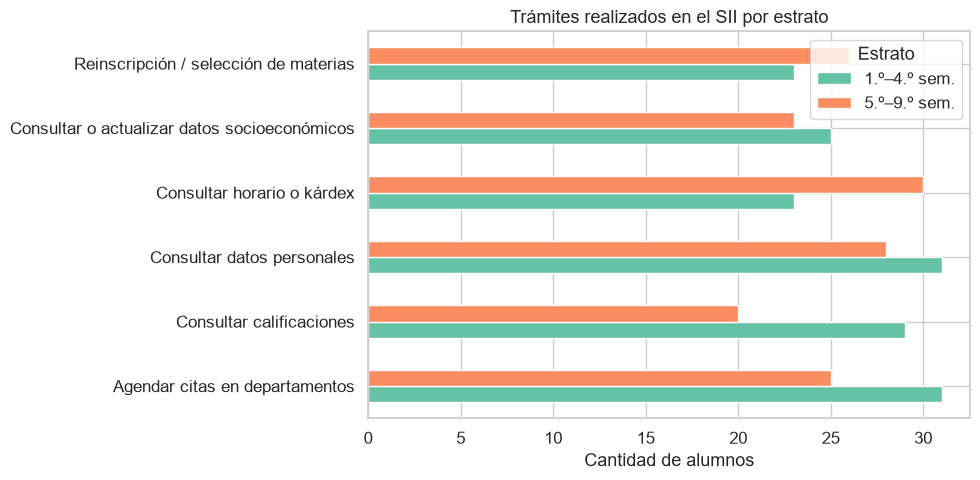

In [18]:
# --- 1.3 Trámites realizados (opción múltiple) ---
cols_tramite = [c for c in df.columns if c.startswith("tramite_")]

# Etiquetas cortas para los trámites
labels_tramite = [c.replace("tramite_", "") for c in cols_tramite]

# Contar por estrato
bloque1 = df[df["bloque"] == "1.º – 4.º semestre"]
bloque2 = df[df["bloque"] == "5.º – 9.º semestre"]

conteo_t = pd.DataFrame({
    "1.º–4.º sem.": bloque1[cols_tramite].sum().values,
    "5.º–9.º sem.": bloque2[cols_tramite].sum().values
}, index=labels_tramite)

print("Cantidad de alumnos que realizaron cada trámite:")
print(conteo_t)

# --- Gráfica de barras horizontales ---
fig, ax = plt.subplots(figsize=(10, 5))
conteo_t.plot(kind="barh", ax=ax, edgecolor="white")
ax.set_title("Trámites realizados en el SII por estrato")
ax.set_xlabel("Cantidad de alumnos")
ax.set_ylabel("")
ax.legend(title="Estrato")
plt.tight_layout()
plt.show()

### 1.4 ¿Cuáles son los principales cuellos de botella técnicos reportados?

Se analizan las 9 variables dummy generadas a partir de `problemas_tipos` (valores 0 y 1). Para cada problema técnico se calcula el porcentaje de incidencia dentro de cada estrato ($\frac{\text{conteo}}{n_k} \times 100$) y se ordenan de mayor a menor frecuencia global para identificar los principales cuellos de botella del sistema.

Incidencia de problemas técnicos (% del estrato):
                                  Total (%)  1.º–4.º sem. (%)  \
Fallas al seleccionar\nmaterias        28.3              28.6   
Fallas al agendar\ncitas               26.8              28.6   
Mala adaptación\nal celular            26.0              21.4   
Lentitud al\ncargar páginas            21.3              21.4   
Información\ndesactualizada            20.5              21.4   
Caídas / Falta\nde conexión            18.1              17.1   
No he tenido\nproblemas                18.1              20.0   
Problemas\nde acceso                   16.5              15.7   
Errores de\ndiseño/visualización       15.7              21.4   

                                  5.º–9.º sem. (%)  
Fallas al seleccionar\nmaterias               28.1  
Fallas al agendar\ncitas                      24.6  
Mala adaptación\nal celular                   31.6  
Lentitud al\ncargar páginas                   21.1  
Información\ndesactualizada       

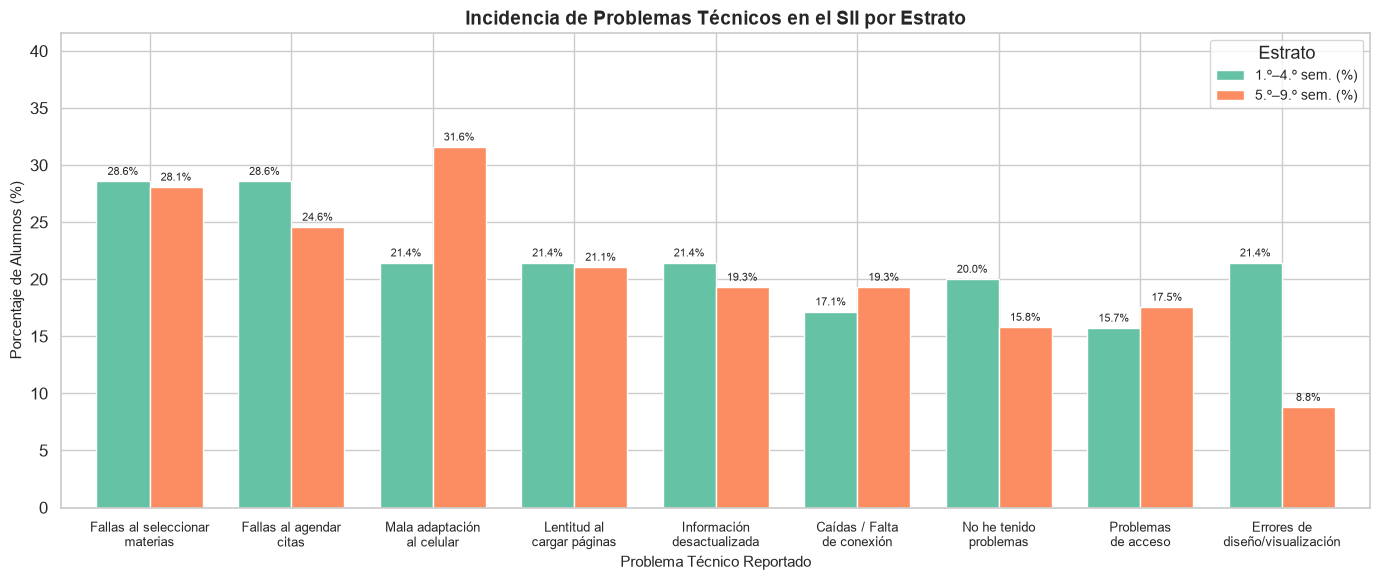

In [19]:
# --- 1.4 Cuellos de botella técnicos reportados en el SII ---
cols_problemas = [
    "problema_Fallas al seleccionar materias",
    "problema_Fallas al agendar citas",
    "problema_Mala adaptación al celular",
    "problema_Lentitud al cargar las páginas",
    "problema_Información incorrecta o desactualizada",
    "problema_Caídas o falta de conexión con el sistema",
    "problema_Problemas de acceso (usuario o contraseña)",
    "problema_Errores de visualización o de diseño",
    "problema_No he tenido problemas"
]

labels_limpios = {
    "problema_Fallas al seleccionar materias": "Fallas al seleccionar\nmaterias",
    "problema_Fallas al agendar citas": "Fallas al agendar\ncitas",
    "problema_Mala adaptación al celular": "Mala adaptación\nal celular",
    "problema_Lentitud al cargar las páginas": "Lentitud al\ncargar páginas",
    "problema_Información incorrecta o desactualizada": "Información\ndesactualizada",
    "problema_Caídas o falta de conexión con el sistema": "Caídas / Falta\nde conexión",
    "problema_Problemas de acceso (usuario o contraseña)": "Problemas\nde acceso",
    "problema_Errores de visualización o de diseño": "Errores de\ndiseño/visualización",
    "problema_No he tenido problemas": "No he tenido\nproblemas"
}

bloque1 = df[df["bloque"] == "1.º – 4.º semestre"]
bloque2 = df[df["bloque"] == "5.º – 9.º semestre"]

# Cálculo de porcentajes por estrato y total
pct_b1 = (bloque1[cols_problemas].mean() * 100).rename("1.º–4.º sem. (%)")
pct_b2 = (bloque2[cols_problemas].mean() * 100).rename("5.º–9.º sem. (%)")
pct_total = (df[cols_problemas].mean() * 100).rename("Total (%)")

df_cuellos = pd.DataFrame([pct_total, pct_b1, pct_b2]).T
df_cuellos = df_cuellos.sort_values("Total (%)", ascending=False)
df_cuellos.index = [labels_limpios.get(c, c) for c in df_cuellos.index]

print("Incidencia de problemas técnicos (% del estrato):")
print(df_cuellos.round(1))

# --- Gráfica de barras agrupada única (columnas dobles por estrato) ---
fig, ax = plt.subplots(figsize=(14, 6))

df_grafica = df_cuellos[["1.º–4.º sem. (%)", "5.º–9.º sem. (%)"]]
df_grafica.plot(kind="bar", ax=ax, edgecolor="white", width=0.75)

ax.set_title("Incidencia de Problemas Técnicos en el SII por Estrato", fontsize=14, fontweight="bold")
ax.set_xlabel("Problema Técnico Reportado", fontsize=11)
ax.set_ylabel("Porcentaje de Alumnos (%)", fontsize=11)
ax.set_ylim(0, max(df_cuellos[["1.º–4.º sem. (%)", "5.º–9.º sem. (%)"]].max()) + 10)
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.legend(title="Estrato", fontsize=10)

# Etiquetas numéricas sobre las barras
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

## Análisis de satisfacción en escala Likert (1–5)

Para cada pregunta de satisfacción se calcula la **media aritmética** (promedio ponderado por frecuencia) por estrato:

$$\bar{X} = \frac{\sum_{i=1}^{n} x_i}{n}$$

Donde $x_i$ es la calificación del alumno $i$ y $n$ es el total de respuestas válidas (excluyendo valores nulos en las preguntas opcionales).

Se presenta la distribución de respuestas (1–5) separada por estrato.

### 2.1 Satisfacción general con el SII

Distribución de respuestas y media por estrato para la columna `sat_general`.

Estrato 1.º–4.º sem.: n=70, media=3.21, DE=1.20
Estrato 5.º–9.º sem.: n=57, media=3.09, DE=1.14
Diferencia de medias: +0.13


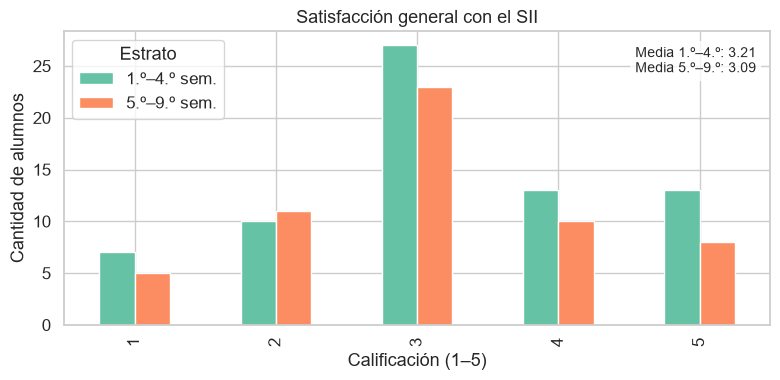

In [20]:
# --- 2.1 Satisfacción general con el SII ---
col = "sat_general"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Satisfacción general con el SII")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.2 Facilidad de uso y navegación

Distribución de respuestas y media por estrato para la columna `sat_facilidad`.

Estrato 1.º–4.º sem.: n=70, media=3.03, DE=0.96
Estrato 5.º–9.º sem.: n=57, media=2.96, DE=0.89
Diferencia de medias: +0.06


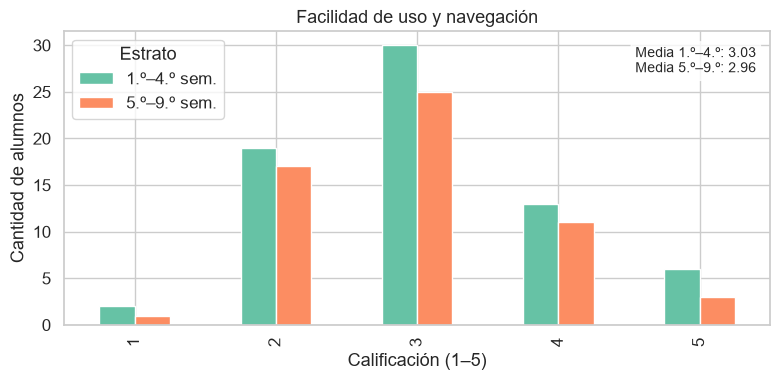

In [21]:
# --- 2.2 Facilidad de uso y navegación ---
col = "sat_facilidad"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Facilidad de uso y navegación")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.3 Diseño y visualización

Distribución de respuestas y media por estrato para la columna `sat_diseno`.

Estrato 1.º–4.º sem.: n=70, media=2.61, DE=1.13
Estrato 5.º–9.º sem.: n=57, media=2.72, DE=0.92
Diferencia de medias: -0.11


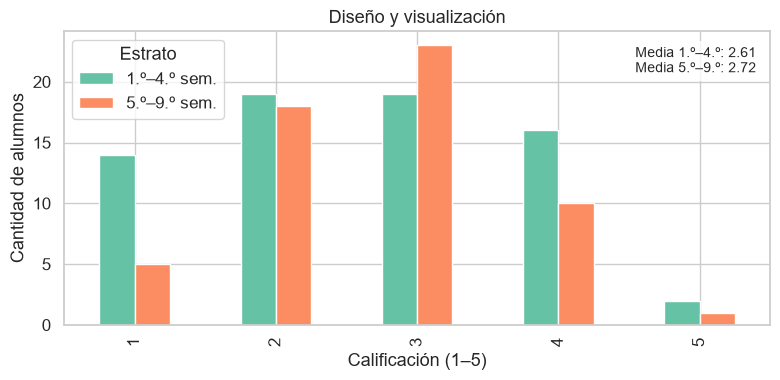

In [22]:
# --- 2.3 Diseño y visualización ---
col = "sat_diseno"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Diseño y visualización")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.4 Velocidad de carga y respuesta

Distribución de respuestas y media por estrato para la columna `sat_rendimiento`.

Estrato 1.º–4.º sem.: n=70, media=2.54, DE=1.11
Estrato 5.º–9.º sem.: n=57, media=2.58, DE=1.07
Diferencia de medias: -0.04


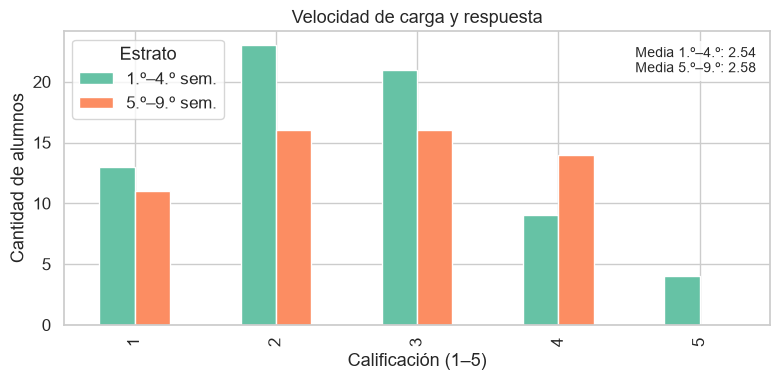

In [23]:
# --- 2.4 Velocidad de carga y respuesta ---
col = "sat_rendimiento"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Velocidad de carga y respuesta")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.5 Disponibilidad del SII

Distribución de respuestas y media por estrato para la columna `sat_disponibilidad`.

Estrato 1.º–4.º sem.: n=70, media=2.89, DE=1.15
Estrato 5.º–9.º sem.: n=57, media=3.18, DE=1.15
Diferencia de medias: -0.29


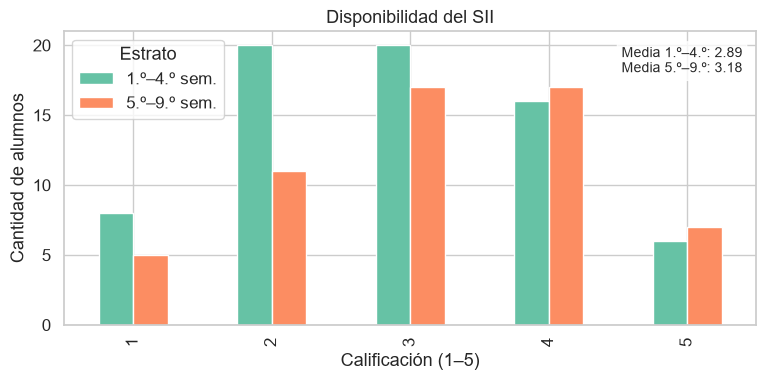

In [24]:
# --- 2.5 Disponibilidad del SII ---
col = "sat_disponibilidad"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Disponibilidad del SII")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.6 Exactitud de información académica

Distribución de respuestas y media por estrato para la columna `sat_info`.

Estrato 1.º–4.º sem.: n=70, media=3.63, DE=1.18
Estrato 5.º–9.º sem.: n=57, media=3.53, DE=1.20
Diferencia de medias: +0.10


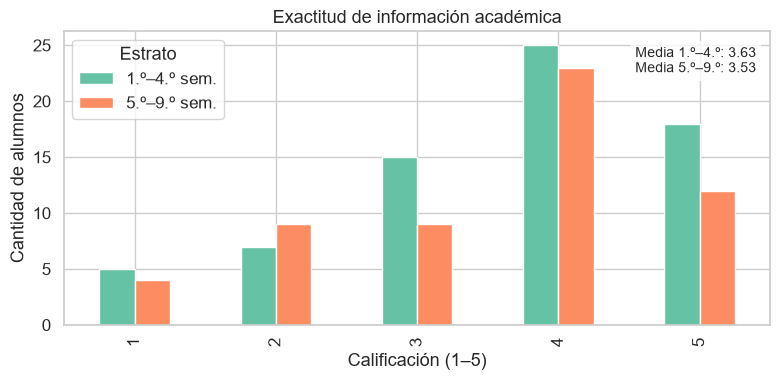

In [25]:
# --- 2.6 Exactitud de información académica ---
col = "sat_info"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Exactitud de información académica")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.7 Seguridad de datos personales

Distribución de respuestas y media por estrato para la columna `sat_seguridad`.

Estrato 1.º–4.º sem.: n=70, media=3.21, DE=1.03
Estrato 5.º–9.º sem.: n=57, media=3.21, DE=1.22
Diferencia de medias: +0.00


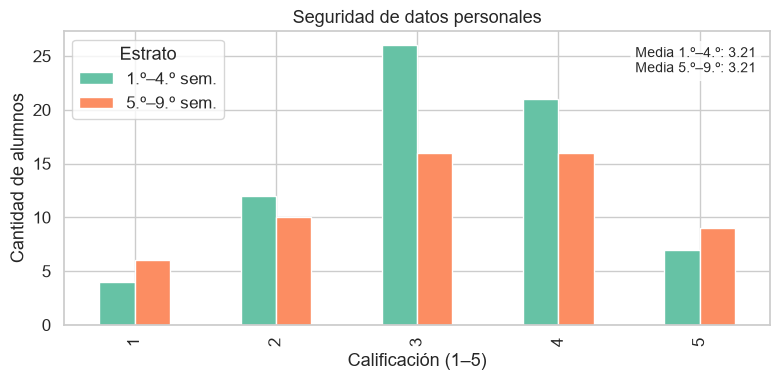

In [26]:
# --- 2.7 Seguridad de datos personales ---
col = "sat_seguridad"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Seguridad de datos personales")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.8 Consulta de calificaciones (opcional)

Distribución de respuestas y media por estrato para la columna `sat_calificaciones`.

Estrato 1.º–4.º sem.: n=59, media=3.34, DE=1.12
Estrato 5.º–9.º sem.: n=54, media=3.43, DE=1.13
Diferencia de medias: -0.09


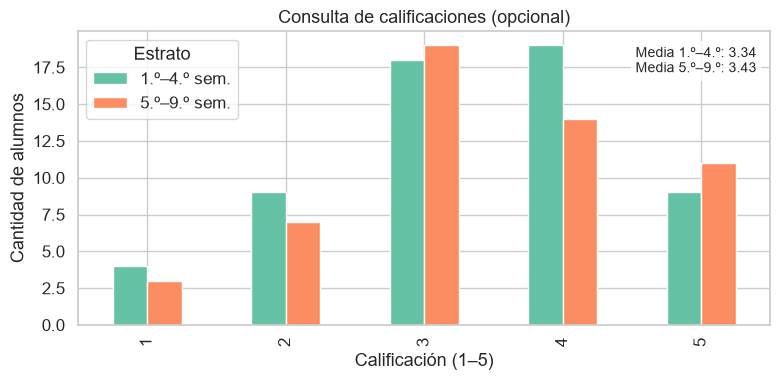

In [27]:
# --- 2.8 Consulta de calificaciones (opcional) ---
col = "sat_calificaciones"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Consulta de calificaciones (opcional)")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.9 Reinscripción y selección de materias (opcional)

Distribución de respuestas y media por estrato para la columna `sat_reinscripcion`.

Estrato 1.º–4.º sem.: n=57, media=2.61, DE=1.35
Estrato 5.º–9.º sem.: n=46, media=2.41, DE=1.02
Diferencia de medias: +0.20


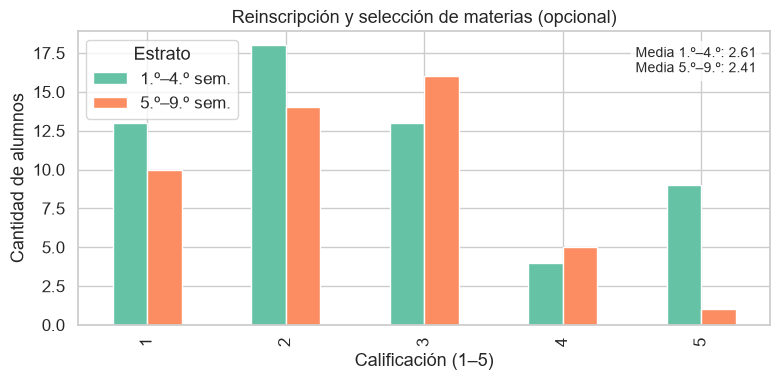

In [28]:
# --- 2.9 Reinscripción y selección de materias (opcional) ---
col = "sat_reinscripcion"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Reinscripción y selección de materias (opcional)")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### 2.10 Agendado de citas (opcional)

Distribución de respuestas y media por estrato para la columna `sat_citas`.

Estrato 1.º–4.º sem.: n=40, media=2.65, DE=1.23
Estrato 5.º–9.º sem.: n=24, media=2.67, DE=1.27
Diferencia de medias: -0.02


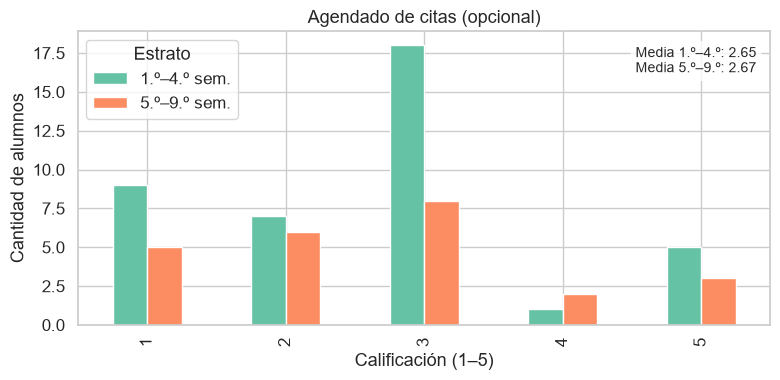

In [29]:
# --- 2.10 Agendado de citas (opcional) ---
col = "sat_citas"

# Filtrar por estrato
b1 = df[df["bloque"] == "1.º – 4.º semestre"][col].dropna()
b2 = df[df["bloque"] == "5.º – 9.º semestre"][col].dropna()

# Calcular medias
media1 = b1.mean()
media2 = b2.mean()

print(f"Estrato 1.º–4.º sem.: n={len(b1)}, media={media1:.2f}, DE={b1.std():.2f}")
print(f"Estrato 5.º–9.º sem.: n={len(b2)}, media={media2:.2f}, DE={b2.std():.2f}")
print(f"Diferencia de medias: {media1 - media2:+.2f}")

# Distribución de respuestas
dist = pd.DataFrame({
    "1.º–4.º sem.": b1.value_counts().reindex([1,2,3,4,5], fill_value=0),
    "5.º–9.º sem.": b2.value_counts().reindex([1,2,3,4,5], fill_value=0)
})

# --- Gráfica de barras ---
fig, ax = plt.subplots(figsize=(8, 4))
dist.plot(kind="bar", ax=ax, edgecolor="white")
ax.set_title("Agendado de citas (opcional)")
ax.set_xlabel("Calificación (1–5)")
ax.set_ylabel("Cantidad de alumnos")
ax.legend(title="Estrato")

# Líneas de media
ax.axhline(y=0, color="gray", linewidth=0.5)
ax.text(0.98, 0.95, f"Media 1.º–4.º: {media1:.2f}\nMedia 5.º–9.º: {media2:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

### Resumen comparativo de satisfacción por estrato

Gráfica resumen con las medias de las 10 dimensiones de satisfacción, comparando ambos estratos lado a lado.

Medias por estrato:
                 1.º–4.º sem.  5.º–9.º sem.
General                  3.21          3.09
Facilidad                3.03          2.96
Diseño                   2.61          2.72
Rendimiento              2.54          2.58
Disponibilidad           2.89          3.18
Info. académica          3.63          3.53
Seguridad                3.21          3.21
Calificaciones           3.34          3.43
Reinscripción            2.61          2.41
Citas                    2.65          2.67

Diferencia (1.º–4.º − 5.º–9.º):
General            0.13
Facilidad          0.06
Diseño            -0.11
Rendimiento       -0.04
Disponibilidad    -0.29
Info. académica    0.10
Seguridad          0.00
Calificaciones    -0.09
Reinscripción      0.20
Citas             -0.02
dtype: float64


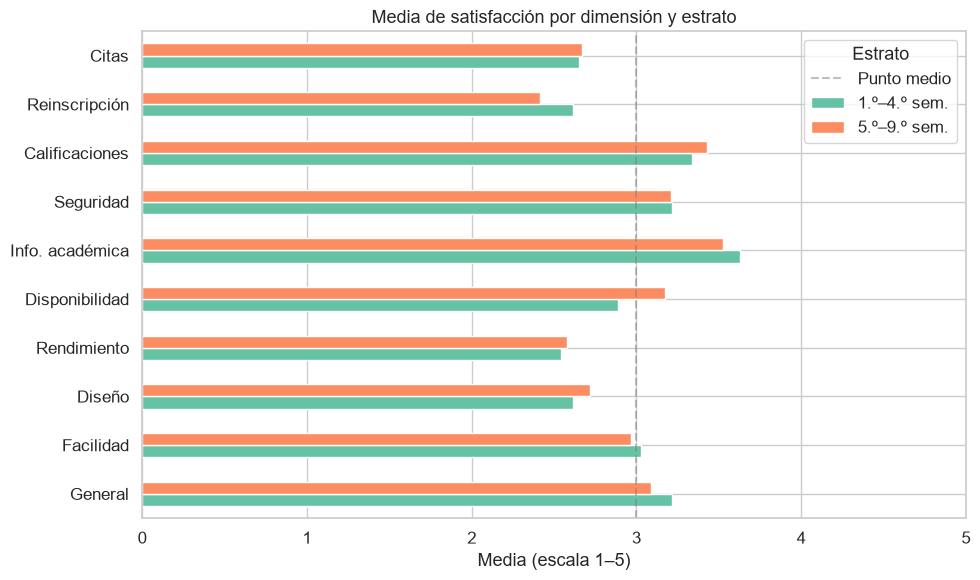

In [30]:
# --- Resumen comparativo de todas las escalas Likert ---
cols_likert = [
    "sat_general", "sat_facilidad", "sat_diseno", "sat_rendimiento",
    "sat_disponibilidad", "sat_info", "sat_seguridad",
    "sat_calificaciones", "sat_reinscripcion", "sat_citas"
]
labels_likert = [
    "General", "Facilidad", "Diseño", "Rendimiento",
    "Disponibilidad", "Info. académica", "Seguridad",
    "Calificaciones", "Reinscripción", "Citas"
]

bloque1 = df[df["bloque"] == "1.º – 4.º semestre"]
bloque2 = df[df["bloque"] == "5.º – 9.º semestre"]

medias = pd.DataFrame({
    "1.º–4.º sem.": [bloque1[c].mean() for c in cols_likert],
    "5.º–9.º sem.": [bloque2[c].mean() for c in cols_likert]
}, index=labels_likert)

print("Medias por estrato:")
print(medias.round(2))
print()
print("Diferencia (1.º–4.º − 5.º–9.º):")
print((medias.iloc[:, 0] - medias.iloc[:, 1]).round(2))

# --- Gráfica de barras horizontales ---
fig, ax = plt.subplots(figsize=(10, 6))
medias.plot(kind="barh", ax=ax, edgecolor="white")
ax.set_title("Media de satisfacción por dimensión y estrato")
ax.set_xlabel("Media (escala 1–5)")
ax.set_ylabel("")
ax.set_xlim(0, 5)
ax.axvline(x=3, color="gray", linestyle="--", alpha=0.5, label="Punto medio")
ax.legend(title="Estrato")
plt.tight_layout()
plt.show()

## Intervalo 1: proporción de satisfacción general (bloque 1.º – 4.º semestre)

Se estima la proporción de estudiantes que se consideran satisfechos con el SII (`satisfecho_binario`) mediante un intervalo de confianza para una proporción con aproximación normal:

$$\hat{p} = \frac{x}{n} \qquad IC = \hat{p} \pm z_{\alpha/2}\sqrt{\frac{\hat{p}\,\hat{q}}{n}}$$

Condición para usar la aproximación normal: $n\hat{p} \geq 10$ y $n\hat{q} \geq 10$.

In [31]:
import numpy as np
from statistics import NormalDist

# Nivel de confianza y valor crítico z (NumPy no incluye la inversa de la normal)
confianza = 0.95
z = NormalDist().inv_cdf(1 - (1 - confianza) / 2)

# Se filtra el bloque 1.º – 4.º semestre
bloque1 = df[df["bloque"] == "1.º – 4.º semestre"]
satisfecho = bloque1["satisfecho_binario"].to_numpy(dtype=bool)

# Estimación puntual: la media de un arreglo booleano es la proporción
n = satisfecho.size
x = satisfecho.sum()
p_hat = satisfecho.mean()
q_hat = 1 - p_hat

print(f"Condición normal: np = {n*p_hat:.0f}, nq = {n*q_hat:.0f}")

# Error estándar, margen de error e intervalo de confianza
error_estandar = np.sqrt(p_hat * q_hat / n)
margen = z * error_estandar
li, ls = p_hat + np.array([-1, 1]) * margen

print(f"n = {n}, x = {x}")
print(f"Estimación puntual p̂ = {p_hat:.4f} ({p_hat:.1%})")
print(f"Error estándar = {error_estandar:.4f}, margen de error = {margen:.4f}")
print(f"IC {confianza:.0%}: [{li:.4f}, {ls:.4f}]  →  [{li:.1%}, {ls:.1%}]")

Condición normal: np = 52, nq = 18
n = 70, x = 52
Estimación puntual p̂ = 0.7429 (74.3%)
Error estándar = 0.0522, margen de error = 0.1024
IC 95%: [0.6405, 0.8452]  →  [64.0%, 84.5%]


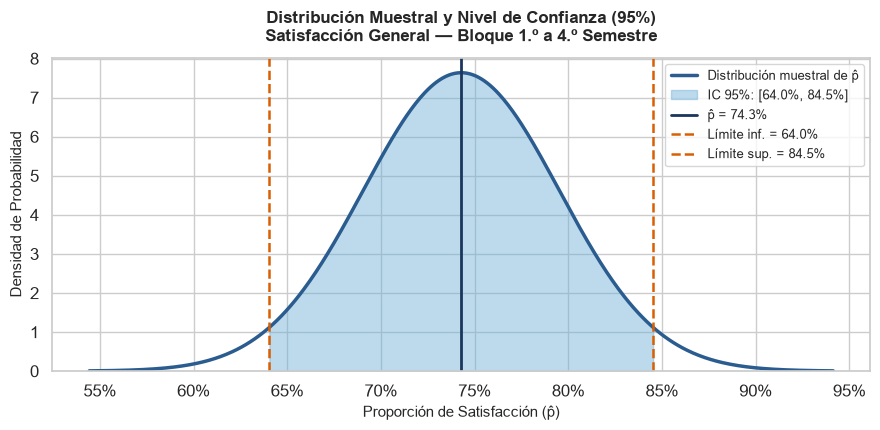

In [32]:
# --- Gráfica de la distribución muestral e Intervalo de Confianza (1.º – 4.º sem.) ---
import matplotlib.ticker as mticker

# Rango del eje x (proporción)
x_vals = np.linspace(p_hat - 3.8 * error_estandar, p_hat + 3.8 * error_estandar, 500)
y_vals = (1 / (error_estandar * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_vals - p_hat) / error_estandar)**2)

fig, ax = plt.subplots(figsize=(9, 4.5))

# Curva normal del estimador
ax.plot(x_vals, y_vals, color="#2b5c8f", lw=2.5, label="Distribución muestral de p̂")

# Área sombreada del 95% de confianza (entre li y ls)
x_ci = np.linspace(li, ls, 300)
y_ci = (1 / (error_estandar * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_ci - p_hat) / error_estandar)**2)
ax.fill_between(x_ci, y_ci, color="#6baed6", alpha=0.45, label=f"IC 95%: [{li:.1%}, {ls:.1%}]")

# Líneas de referencia
ax.axvline(p_hat, color="#1a365d", linestyle="-", lw=2, label=f"p̂ = {p_hat:.1%}")
ax.axvline(li, color="#d95f02", linestyle="--", lw=1.8, label=f"Límite inf. = {li:.1%}")
ax.axvline(ls, color="#d95f02", linestyle="--", lw=1.8, label=f"Límite sup. = {ls:.1%}")

ax.set_title("Distribución Muestral y Nivel de Confianza (95%)\nSatisfacción General — Bloque 1.º a 4.º Semestre", 
             fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Proporción de Satisfacción (p̂)", fontsize=11)
ax.set_ylabel("Densidad de Probabilidad", fontsize=11)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper right", frameon=True, fontsize=9.5)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

### Interpretación

- **Estimación puntual:** $\hat{p} = 53/74 = 0.7428$; es decir, el 74.3 % de los estudiantes de 1.º a 4.º semestre se considera satisfecho con el SII.
- **Condición normal:** $n\hat{p} = 52$ y $n\hat{q} = 18$, ambos $\geq 10$, por lo que la aproximación normal es válida.
- **Intervalo de confianza al 95 %:** $[0.6405,\ 0.8452]$.

Con un 95 % de confianza, la proporción de estudiantes de 1.º a 4.º semestre de ISC del ITVER que se consideran satisfechos con el SII se encuentra entre el **64.0 %** y el **84.5 %**.

## Intervalo 2: proporción de satisfacción general (bloque 5.º – 9.º semestre)

Se aplica el mismo procedimiento del Intervalo 1 al bloque de 5.º a 9.º semestre, con el mismo nivel de confianza (95 %):

$$\hat{p} = \frac{x}{n} \qquad IC = \hat{p} \pm z_{\alpha/2}\sqrt{\frac{\hat{p}\,\hat{q}}{n}}$$

Condición para usar la aproximación normal: $n\hat{p} \geq 10$ y $n\hat{q} \geq 10$.

In [33]:
# Se reutilizan 'confianza' y 'z' del Intervalo 1

# Se filtra el bloque 5.º – 9.º semestre
bloque2 = df[df["bloque"] == "5.º – 9.º semestre"]
satisfecho2 = bloque2["satisfecho_binario"].to_numpy(dtype=bool)

# Estimación puntual: la media de un arreglo booleano es la proporción
n2 = satisfecho2.size
x2 = satisfecho2.sum()
p_hat2 = satisfecho2.mean()
q_hat2 = 1 - p_hat2

print(f"Condición normal: np = {n2*p_hat2:.0f}, nq = {n2*q_hat2:.0f}")

# Error estándar, margen de error e intervalo de confianza
error_estandar2 = np.sqrt(p_hat2 * q_hat2 / n2)
margen2 = z * error_estandar2
li2, ls2 = p_hat2 + np.array([-1, 1]) * margen2

print(f"n = {n2}, x = {x2}")
print(f"Estimación puntual p̂ = {p_hat2:.4f} ({p_hat2:.1%})")
print(f"Error estándar = {error_estandar2:.4f}, margen de error = {margen2:.4f}")
print(f"IC {confianza:.0%}: [{li2:.4f}, {ls2:.4f}]  →  [{li2:.1%}, {ls2:.1%}]")

Condición normal: np = 27, nq = 30
n = 57, x = 27
Estimación puntual p̂ = 0.4737 (47.4%)
Error estándar = 0.0661, margen de error = 0.1296
IC 95%: [0.3441, 0.6033]  →  [34.4%, 60.3%]


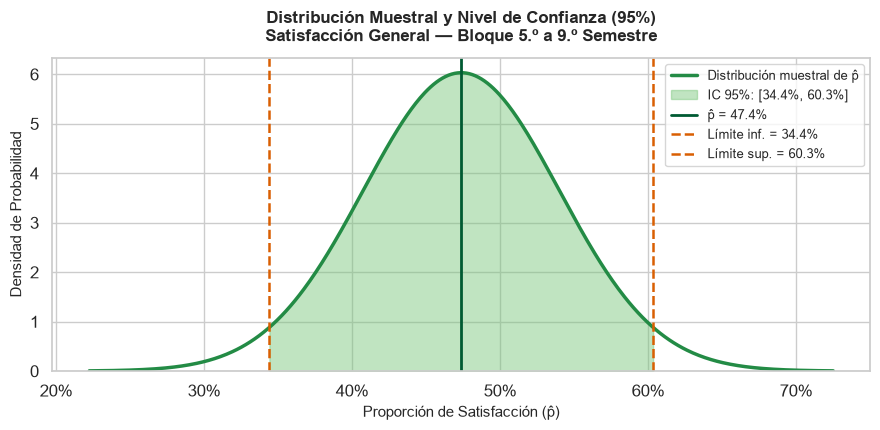

In [34]:
# --- Gráfica de la distribución muestral e Intervalo de Confianza (5.º – 9.º sem.) ---
import matplotlib.ticker as mticker

# Rango del eje x (proporción)
x_vals2 = np.linspace(p_hat2 - 3.8 * error_estandar2, p_hat2 + 3.8 * error_estandar2, 500)
y_vals2 = (1 / (error_estandar2 * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_vals2 - p_hat2) / error_estandar2)**2)

fig, ax = plt.subplots(figsize=(9, 4.5))

# Curva normal del estimador
ax.plot(x_vals2, y_vals2, color="#238b45", lw=2.5, label="Distribución muestral de p̂")

# Área sombreada del 95% de confianza (entre li2 y ls2)
x_ci2 = np.linspace(li2, ls2, 300)
y_ci2 = (1 / (error_estandar2 * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_ci2 - p_hat2) / error_estandar2)**2)
ax.fill_between(x_ci2, y_ci2, color="#74c476", alpha=0.45, label=f"IC 95%: [{li2:.1%}, {ls2:.1%}]")

# Líneas de referencia
ax.axvline(p_hat2, color="#005a32", linestyle="-", lw=2, label=f"p̂ = {p_hat2:.1%}")
ax.axvline(li2, color="#d95f02", linestyle="--", lw=1.8, label=f"Límite inf. = {li2:.1%}")
ax.axvline(ls2, color="#d95f02", linestyle="--", lw=1.8, label=f"Límite sup. = {ls2:.1%}")

ax.set_title("Distribución Muestral y Nivel de Confianza (95%)\nSatisfacción General — Bloque 5.º a 9.º Semestre", 
             fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Proporción de Satisfacción (p̂)", fontsize=11)
ax.set_ylabel("Densidad de Probabilidad", fontsize=11)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper right", frameon=True, fontsize=9.5)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

### Interpretación

- **Estimación puntual:** $\hat{p} = 27/57 = 0.4747$; es decir, el 47.4 % de los estudiantes de 5.º a 9.º semestre se considera satisfecho con el SII.
- **Condición normal:** $n\hat{p} = 27$ y $n\hat{q} = 30$, ambos $\geq 10$, por lo que la aproximación normal es válida.
- **Intervalo de confianza al 95 %:** $[0.3441,\ 0.6033]$.

Con un 95 % de confianza, la proporción de estudiantes de 5.º a 9.º semestre de ISC del ITVER que se consideran satisfechos con el SII se encuentra entre el **34.4 %** y el **60.3 %**.

## Diferencia de proporciones: Intervalo 1 vs. Intervalo 2

Se construye un intervalo de confianza para la diferencia entre la proporción de satisfacción del bloque 1.º – 4.º semestre ($p_1$) y la del bloque 5.º – 9.º semestre ($p_2$), con el mismo nivel de confianza (95 %):

$$\hat{p}_1 - \hat{p}_2 \qquad IC = (\hat{p}_1 - \hat{p}_2) \pm z_{\alpha/2}\sqrt{\frac{\hat{p}_1\,\hat{q}_1}{n_1} + \frac{\hat{p}_2\,\hat{q}_2}{n_2}}$$

Criterio de decisión: si el intervalo **contiene el 0**, no hay evidencia estadística de que las proporciones de ambos bloques sean diferentes.

In [35]:
# Se reutilizan los resultados del Intervalo 1 (p_hat, q_hat, n) y del Intervalo 2 (p_hat2, q_hat2, n2)

# Estimación puntual de la diferencia
diferencia = p_hat - p_hat2

# Error estándar, margen de error e intervalo de confianza de la diferencia
error_estandar_dif = np.sqrt(p_hat * q_hat / n + p_hat2 * q_hat2 / n2)
margen_dif = z * error_estandar_dif
li_dif, ls_dif = diferencia + np.array([-1, 1]) * margen_dif

print(f"p̂1 = {p_hat:.4f}, p̂2 = {p_hat2:.4f}")
print(f"Estimación puntual p̂1 - p̂2 = {diferencia:.4f} ({diferencia:.1%})")
print(f"Error estándar = {error_estandar_dif:.4f}, margen de error = {margen_dif:.4f}")
print(f"IC {confianza:.0%}: [{li_dif:.4f}, {ls_dif:.4f}]  →  [{li_dif:.1%}, {ls_dif:.1%}]")

# Criterio de decisión
if li_dif <= 0 <= ls_dif:
    print("El intervalo contiene el 0: no hay diferencia significativa entre los bloques.")
else:
    print("El intervalo no contiene el 0: la diferencia entre los bloques es significativa.")

p̂1 = 0.7429, p̂2 = 0.4737
Estimación puntual p̂1 - p̂2 = 0.2692 (26.9%)
Error estándar = 0.0843, margen de error = 0.1652
IC 95%: [0.1040, 0.4344]  →  [10.4%, 43.4%]
El intervalo no contiene el 0: la diferencia entre los bloques es significativa.


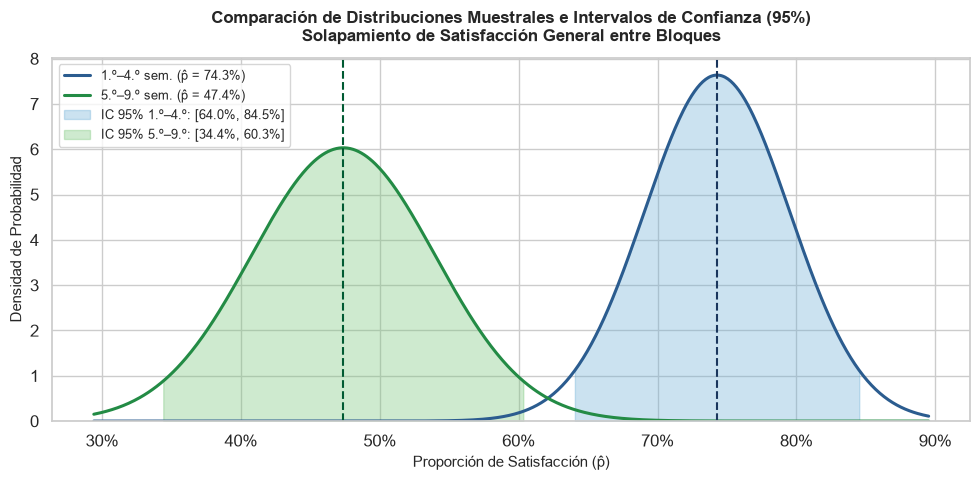

In [36]:
# --- Gráfica comparativa superpuesta de distribuciones (1.º–4.º vs. 5.º–9.º sem.) ---
import matplotlib.ticker as mticker

x_min = min(li2 - 0.05, li - 0.05)
x_max = max(ls2 + 0.05, ls + 0.05)
x_axis = np.linspace(x_min, x_max, 600)

y_dist1 = (1 / (error_estandar * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_axis - p_hat) / error_estandar)**2)
y_dist2 = (1 / (error_estandar2 * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_axis - p_hat2) / error_estandar2)**2)

fig, ax = plt.subplots(figsize=(10, 5))

# Curvas normales de ambos estratos
ax.plot(x_axis, y_dist1, color="#2b5c8f", lw=2.2, label=f"1.º–4.º sem. (p̂ = {p_hat:.1%})")
ax.plot(x_axis, y_dist2, color="#238b45", lw=2.2, label=f"5.º–9.º sem. (p̂ = {p_hat2:.1%})")

# Relleno de IC 95% de cada bloque para observar el solapamiento
x_ci1 = np.linspace(li, ls, 300)
y_ci1 = (1 / (error_estandar * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_ci1 - p_hat) / error_estandar)**2)
ax.fill_between(x_ci1, y_ci1, color="#6baed6", alpha=0.35, label=f"IC 95% 1.º–4.º: [{li:.1%}, {ls:.1%}]")

x_ci2 = np.linspace(li2, ls2, 300)
y_ci2 = (1 / (error_estandar2 * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_ci2 - p_hat2) / error_estandar2)**2)
ax.fill_between(x_ci2, y_ci2, color="#74c476", alpha=0.35, label=f"IC 95% 5.º–9.º: [{li2:.1%}, {ls2:.1%}]")

# Líneas de estimación puntual
ax.axvline(p_hat, color="#1a365d", linestyle="--", lw=1.5)
ax.axvline(p_hat2, color="#005a32", linestyle="--", lw=1.5)

ax.set_title("Comparación de Distribuciones Muestrales e Intervalos de Confianza (95%)\nSolapamiento de Satisfacción General entre Bloques", 
             fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Proporción de Satisfacción (p̂)", fontsize=11)
ax.set_ylabel("Densidad de Probabilidad", fontsize=11)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper left", frameon=True, fontsize=9.5)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

### Interpretación

- **Estimación puntual:** $\hat{p}_1 - \hat{p}_2 = 0.7429 - 0.4737 = 0.2692$; es decir, la proporción de satisfacción del bloque 1.º – 4.º semestre es 4.95 puntos porcentuales mayor que la del bloque 5.º – 9.º semestre en la muestra.
- **Error estándar:** $0.0843$; **margen de error:** $0.1652$.
- **Intervalo de confianza al 95 %:** $[0.1040,\ 0.4344]$.

Con un 95 % de confianza, la diferencia entre la proporción de estudiantes satisfechos con el SII del bloque 1.º – 4.º semestre y la del bloque 5.º – 9.º semestre se encuentra entre **10.4** y **43.4** puntos porcentuales.

Como el intervalo **no contiene el 0**,Al ser el límite inferior estrictamente positivo (**10.4** %), existe evidencia estadística suficiente para afirmar que la satisfacción de los estudiantes en semestres iniciales es significativamente mayor que la de los semestres avanzados dentro de la población de ISC del ITVER.